# DSCI 552 — Homework 4
**Haoran Zhang**

## 1. Time Series Classification: Feature Creation and Extraction

I include the HW3 feature code here because HW4 uses it. The train/test split follows the assignment.


In [11]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from IPython.display import display

DATA_DIR = Path("AReM")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]

### 1(a). Load the data

Each file is one recording with six sensor series. The reader skips comment lines and accepts comma- or space-separated values.

One file, `sitting/dataset8.csv`, has 479 rows instead of 480, so I use the values in the file. `bending2/dataset4.csv` is space-separated.


In [12]:
def read_instance(path):
    rows = []
    for line_number, line in enumerate(path.read_text().splitlines(), start=1):
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        values = re.split(r"[,\s]+", line.strip(" ,"))
        if len(values) != 7:
            raise ValueError(f"{path}, line {line_number}: expected 7 values")
        rows.append([float(v) for v in values])
    df = pd.DataFrame(rows, columns=["time"] + SERIES)
    assert np.isfinite(df.to_numpy()).all(), f"Invalid numeric values: {path}"
    assert df["time"].is_monotonic_increasing, f"Time order problem: {path}"
    return df

instances = []
for activity in ACTIVITIES:
    files = sorted((DATA_DIR / activity).glob("dataset*.csv"),
                   key=lambda p: int(re.search(r"dataset(\d+)", p.name).group(1)))
    for path in files:
        number = int(re.search(r"dataset(\d+)", path.name).group(1))
        instances.append({"activity": activity, "dataset": number,
                          "file": f"{activity}/{path.name}", "data": read_instance(path)})
assert len(instances) == 88
inventory = pd.DataFrame([{ "activity": x["activity"], "dataset": x["dataset"],
                           "file": x["file"], "observations": len(x["data"])} for x in instances])
display(inventory.groupby("activity").agg(instances=("file", "size"),
        min_observations=("observations", "min"), max_observations=("observations", "max")))
print("Total instances:", len(instances))
display(inventory[inventory.observations != 480])

,instances,min_observations,max_observations
activity,,,
bending1,7,480,480
bending2,6,480,480
cycling,15,480,480
lying,15,480,480
sitting,15,479,480
standing,15,480,480
walking,15,480,480


Total instances: 88


,activity,dataset,file,observations
50,sitting,8,sitting/dataset8.csv,479


### 1(b). Training and test split
For bending1 and bending2, datasets 1 and 2 go into the test set. For the other activities, datasets 1, 2, and 3 go into the test set. The remaining files form the training set: **69 training instances and 19 test instances**.

In [13]:
for item in instances:
    cutoff = 2 if item["activity"] in ["bending1", "bending2"] else 3
    item["split"] = "test" if item["dataset"] <= cutoff else "train"
split_table = pd.DataFrame([{k: x[k] for k in ["activity", "dataset", "file", "split"]}
                            for x in instances])
display(pd.crosstab(split_table.activity, split_table.split).reindex(ACTIVITIES))
assert (split_table.split == "train").sum() == 69
assert (split_table.split == "test").sum() == 19
split_table.to_csv(RESULTS_DIR / "split_manifest.csv", index=False)

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


### 1(c)(i). Common time-domain features

Common time-domain features include the minimum, maximum, mean, median, standard deviation, variance, and quartiles. Skewness, kurtosis, RMS, energy, and autocorrelation are also used. These summarize a signal's level, spread, shape, or changes over time.

Reference: [tsfresh feature list](https://tsfresh.readthedocs.io/en/latest/text/list_of_features.html).


### 1(c)(ii). Extract features
For each series, I calculate minimum, maximum, mean, median, standard deviation, first quartile, and third quartile. Six series with seven statistics give **42 features** per recording. The table has **88 rows**.

I use sample standard deviation (`ddof=1`) and linear interpolation for quartiles. For example, `q1_6` is the first quartile of series 6.

In [14]:
def extract_features(df):
    features = {}
    for i, name in enumerate(SERIES, start=1):
        x = df[name]
        values = {"min": x.min(), "max": x.max(), "mean": x.mean(),
                  "median": x.median(), "std": x.std(ddof=1),
                  "q1": x.quantile(0.25), "q3": x.quantile(0.75)}
        features.update({f"{stat}_{i}": value for stat, value in values.items()})
    return features

X = pd.DataFrame([extract_features(item["data"]) for item in instances])
metadata = split_table.copy()
metadata.insert(0, "instance", np.arange(1, len(instances) + 1))
features = pd.concat([metadata, X], axis=1)
assert X.shape == (88, 42)
assert np.isfinite(X.to_numpy()).all()
assert all((X[f"min_{i}"] <= X[f"q1_{i}"]).all() and
           (X[f"q1_{i}"] <= X[f"median_{i}"]).all() and
           (X[f"median_{i}"] <= X[f"q3_{i}"]).all() and
           (X[f"q3_{i}"] <= X[f"max_{i}"]).all() for i in range(1, 7))
print("Numeric feature matrix shape:", X.shape)
display(features.head())
features.to_csv(RESULTS_DIR / "features_all.csv", index=False)
features[features.split == "train"].to_csv(RESULTS_DIR / "features_train.csv", index=False)
features[features.split == "test"].to_csv(RESULTS_DIR / "features_test.csv", index=False)

Numeric feature matrix shape: (88, 42)


,instance,activity,dataset,file,split,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1,min_2,max_2,mean_2,median_2,std_2,q1_2,q3_2,min_3,max_3,mean_3,median_3,std_3,q1_3,q3_3,min_4,max_4,mean_4,median_4,std_4,q1_4,q3_4,min_5,max_5,mean_5,median_5,std_5,q1_5,q3_5,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
0,1,bending1,1,bending1/dataset1.csv,test,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,0.43,0.322605,0.00,0.50,4.0,29.50,19.040937,19.250,4.462952,16.00,23.2500,0.0,7.23,0.832542,0.50,0.965659,0.00,1.120,27.25,38.25,34.311292,35.0,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,2,bending1,2,bending1/dataset2.csv,test,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,0.47,0.289158,0.00,0.50,2.0,29.50,20.096979,21.000,3.893737,19.00,22.2500,0.0,5.76,0.876438,0.50,1.047259,0.00,1.145,27.67,38.50,33.024583,33.0,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,3,bending1,3,bending1/dataset3.csv,train,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,0.47,0.338690,0.00,0.50,6.5,29.75,22.122354,23.000,3.030943,19.75,24.0000,0.0,4.44,0.497312,0.43,0.550657,0.00,0.830,29.00,38.50,35.588458,36.0,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,4,bending1,4,bending1/dataset4.csv,train,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,0.50,0.630860,0.00,1.12,8.5,30.00,22.183625,23.000,3.810469,20.50,24.3725,0.0,5.15,0.989917,0.83,0.953730,0.43,1.300,20.00,38.67,33.493917,35.0,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,5,bending1,5,bending1/dataset5.csv,train,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,0.50,0.405469,0.43,0.71,3.0,28.25,19.006563,19.125,4.087107,16.50,22.0625,0.0,6.42,0.841875,0.50,0.928801,0.43,1.120,23.67,37.50,29.857083,30.0,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


### 1(c)(iii). Standard deviations and 90% bootstrap intervals

I calculate the standard deviation of each feature across the 88 recordings. This is different from `std_1`, which is the standard deviation within one recording.

For the bootstrap, I resample 88 recordings with replacement 10,000 times (seed 552). The 5th and 95th percentiles give a 90% interval for each feature. Recordings are pooled across activities, so these intervals do not account for activity groups separately.


In [15]:
def bootstrap_feature_sd(frame, n_bootstrap=10000, seed=552, batch_size=250):
    values = frame.to_numpy(dtype=float)
    n, p = values.shape
    rng = np.random.default_rng(seed)
    bootstrap_sd = np.empty((n_bootstrap, p))
    for start in range(0, n_bootstrap, batch_size):
        stop = min(start + batch_size, n_bootstrap)
        indices = rng.integers(0, n, size=(stop - start, n))
        bootstrap_sd[start:stop] = values[indices].std(axis=1, ddof=1)
    bounds = np.quantile(bootstrap_sd, [0.05, 0.95], axis=0)
    return pd.DataFrame({"feature": frame.columns, "sample_sd": values.std(axis=0, ddof=1),
                         "ci_90_lower": bounds[0], "ci_90_upper": bounds[1]})

sd_ci = bootstrap_feature_sd(X)
assert len(sd_ci) == 42
assert (sd_ci.ci_90_lower <= sd_ci.ci_90_upper).all()
display(sd_ci.round(4))
sd_ci.to_csv(RESULTS_DIR / "feature_sd_bootstrap_90.csv", index=False)

,feature,sample_sd,ci_90_lower,ci_90_upper
0,min_1,9.5700,8.2622,10.7614
1,max_1,4.3944,3.3280,5.2849
2,mean_1,5.3357,4.7040,5.8864
3,median_1,5.4401,4.7903,6.0043
4,std_1,1.7722,1.5722,1.9500
5,q1_1,6.1536,5.5816,6.6524
6,q3_1,5.1389,4.3319,5.8409
7,min_2,0.0000,0.0000,0.0000
8,max_2,5.0627,4.6228,5.4022
9,mean_2,1.5742,1.3941,1.7068


### 1(c)(iv). Three important features

I chose **mean, standard deviation, and maximum**. Mean describes the signal level, standard deviation describes its variation, and maximum captures a peak that the mean could miss. Maximum can be sensitive to outliers. Applying these three statistics to all six series gives 18 features.


In [16]:
selected_columns = [f"{stat}_{i}" for i in range(1, 7) for stat in ["mean", "std", "max"]]
selected_features = pd.concat([metadata, X[selected_columns]], axis=1)
print("Chosen statistic types: mean, standard deviation, maximum")
print("Number of retained numeric columns:", len(selected_columns))
display(selected_features.head())
selected_features.to_csv(RESULTS_DIR / "selected_features.csv", index=False)

Chosen statistic types: mean, standard deviation, maximum
Number of retained numeric columns: 18


,instance,activity,dataset,file,split,mean_1,std_1,max_1,mean_2,std_2,max_2,mean_3,std_3,max_3,mean_4,std_4,max_4,mean_5,std_5,max_5,mean_6,std_6,max_6
0,1,bending1,1,bending1/dataset1.csv,test,40.624792,1.476967,45.00,0.358604,0.322605,1.30,19.040937,4.462952,29.50,0.832542,0.965659,7.23,34.311292,2.188449,38.25,0.570583,0.582915,1.92
1,2,bending1,2,bending1/dataset2.csv,test,42.812812,1.435550,45.67,0.372437,0.289158,1.22,20.096979,3.893737,29.50,0.876438,1.047259,5.76,33.024583,1.995255,38.50,0.571083,0.601010,3.11
2,3,bending1,3,bending1/dataset3.csv,train,43.954500,1.558835,47.40,0.426250,0.338690,1.70,22.122354,3.030943,29.75,0.497312,0.550657,4.44,35.588458,1.999604,38.50,0.493292,0.513506,1.79
3,4,bending1,4,bending1/dataset4.csv,train,42.179812,3.670666,47.75,0.696042,0.630860,3.00,22.183625,3.810469,30.00,0.989917,0.953730,5.15,33.493917,3.849448,38.67,0.613521,0.524317,2.18
4,5,bending1,5,bending1/dataset5.csv,train,41.678063,2.243490,45.75,0.535979,0.405469,2.83,19.006563,4.087107,28.25,0.841875,0.928801,6.42,29.857083,2.411026,37.50,0.383292,0.389164,1.79


## 2. Time Series Classification: Binary and Multiclass Classification

### 2(a)(i). Bending versus other activities

These pair plots use the selected mean, standard deviation, and maximum for series 1, 2, and 6. They show training recordings only; color indicates bending or other activity.


### Packages

This notebook uses numpy, pandas, scipy, scikit-learn, matplotlib, and seaborn. Install any that are missing from your Python environment before running the notebook.


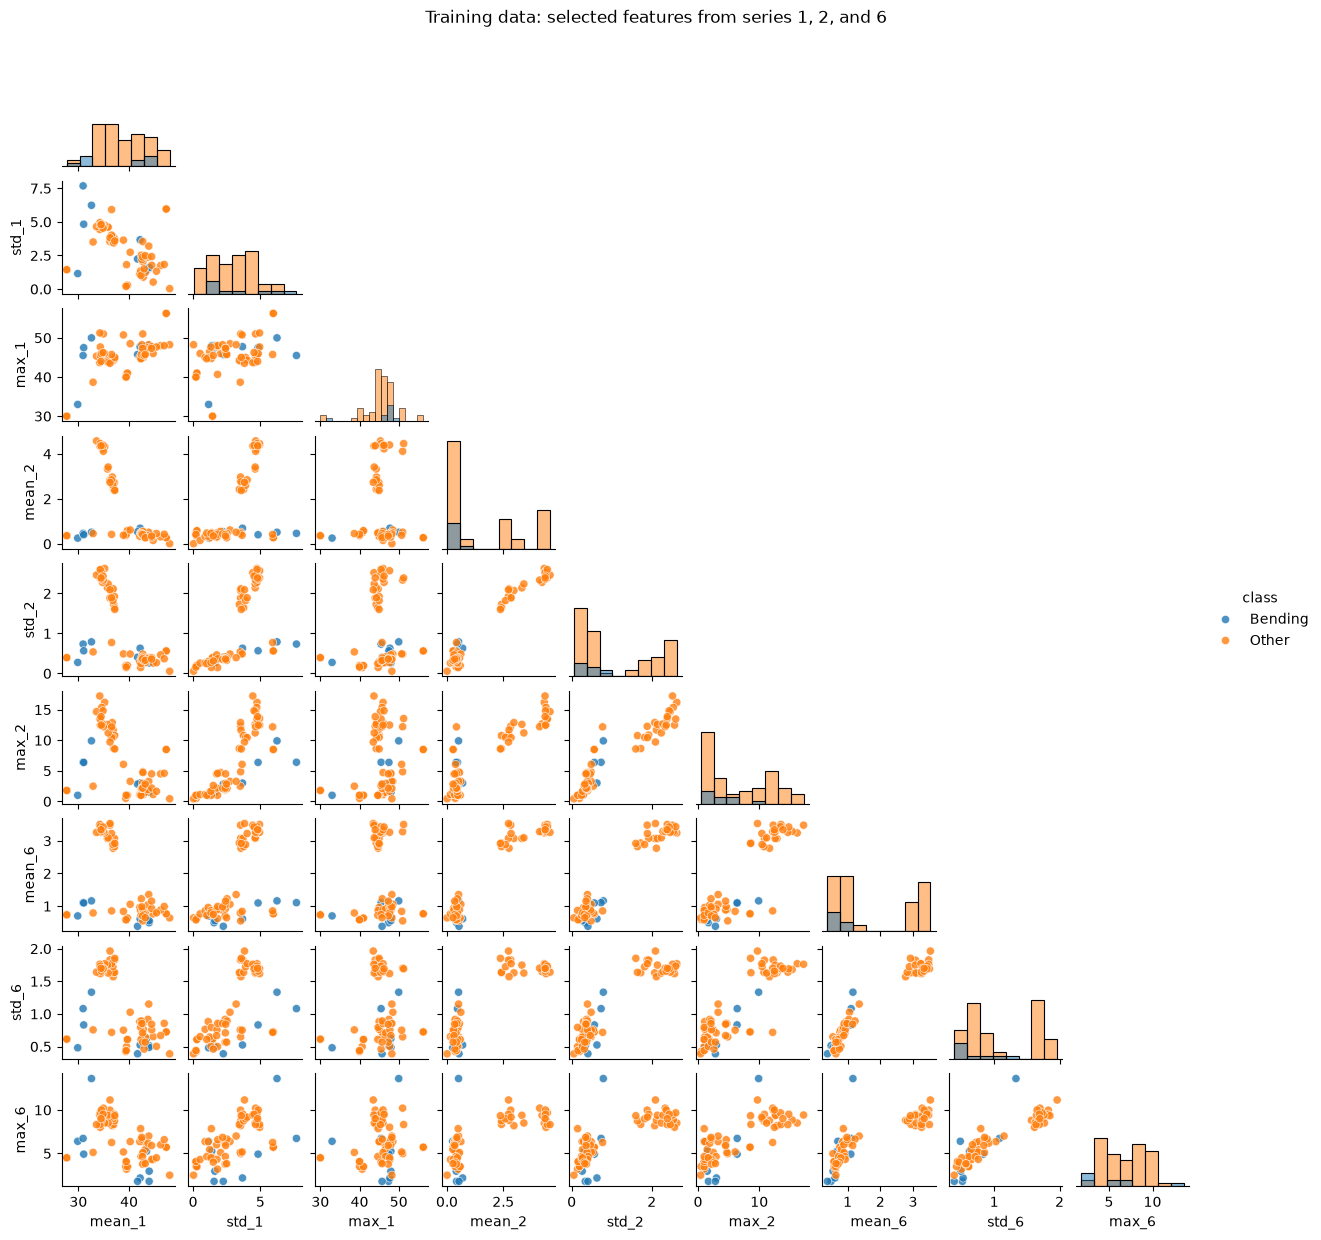

Training class counts: {'Other': 60, 'Bending': 9}


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             classification_report, roc_auc_score, roc_curve)
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from scipy.special import expit, logit
from scipy.stats import norm

train_idx = split_table[split_table.split == "train"].index
test_idx = split_table[split_table.split == "test"].index
y_all = np.array([1 if x["activity"].startswith("bending") else 0 for x in instances])
y_train, y_test = y_all[train_idx], y_all[test_idx]
labels_binary = np.where(y_train == 1, "Bending", "Other")
plot_cols = [f"{stat}_{j}" for j in [1, 2, 6] for stat in ["mean", "std", "max"]]
plot_df = X.loc[train_idx, plot_cols].copy()
plot_df["class"] = labels_binary
sns.pairplot(plot_df, vars=plot_cols, hue="class", corner=True, diag_kind="hist", height=1.35,
             plot_kws={"alpha": 0.8, "s": 35})
plt.suptitle("Training data: selected features from series 1, 2, and 6", y=1.02)
plt.show()
print("Training class counts:", pd.Series(labels_binary).value_counts().to_dict())


**What I see:** Bending and other activities overlap for several features, especially in series 1 and 6. The series 2 mean and standard deviation show clearer groups, although there are still a few overlapping points. There are only nine bending training recordings, so the plots are hard to judge from alone.


### 2(a)(ii). Features from the two halves

I split series 1, 2, and 6 into two parts and calculate mean, standard deviation, and maximum for each part. The plots below show the first and second halves separately.


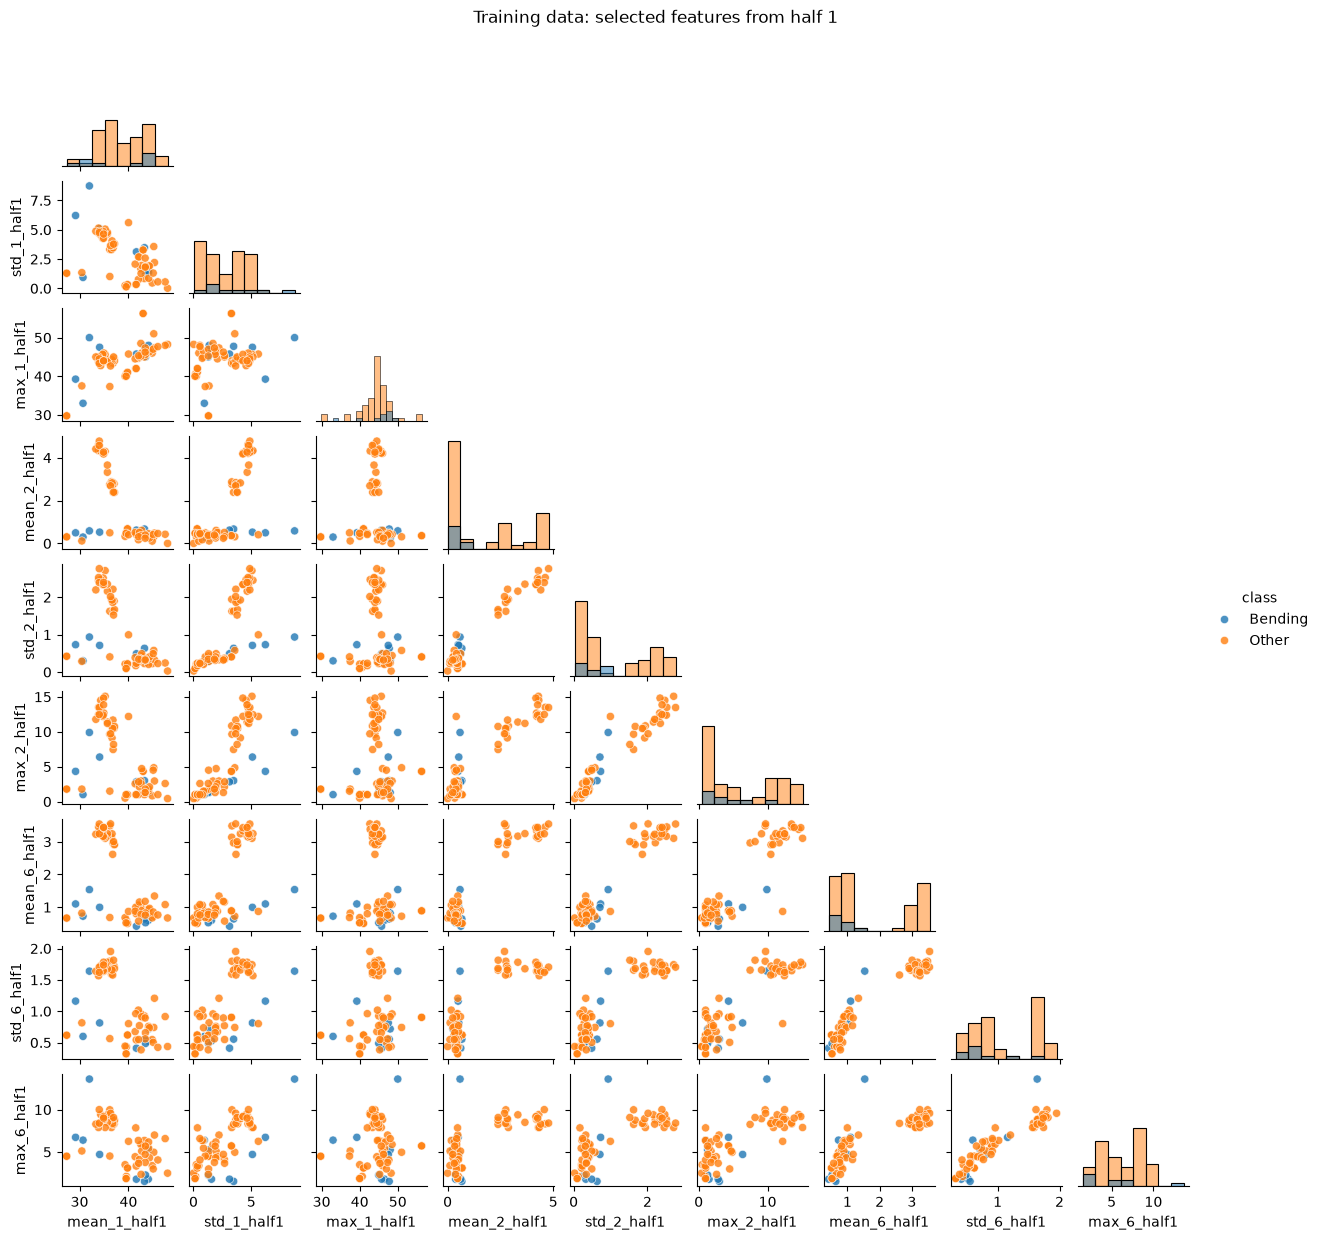

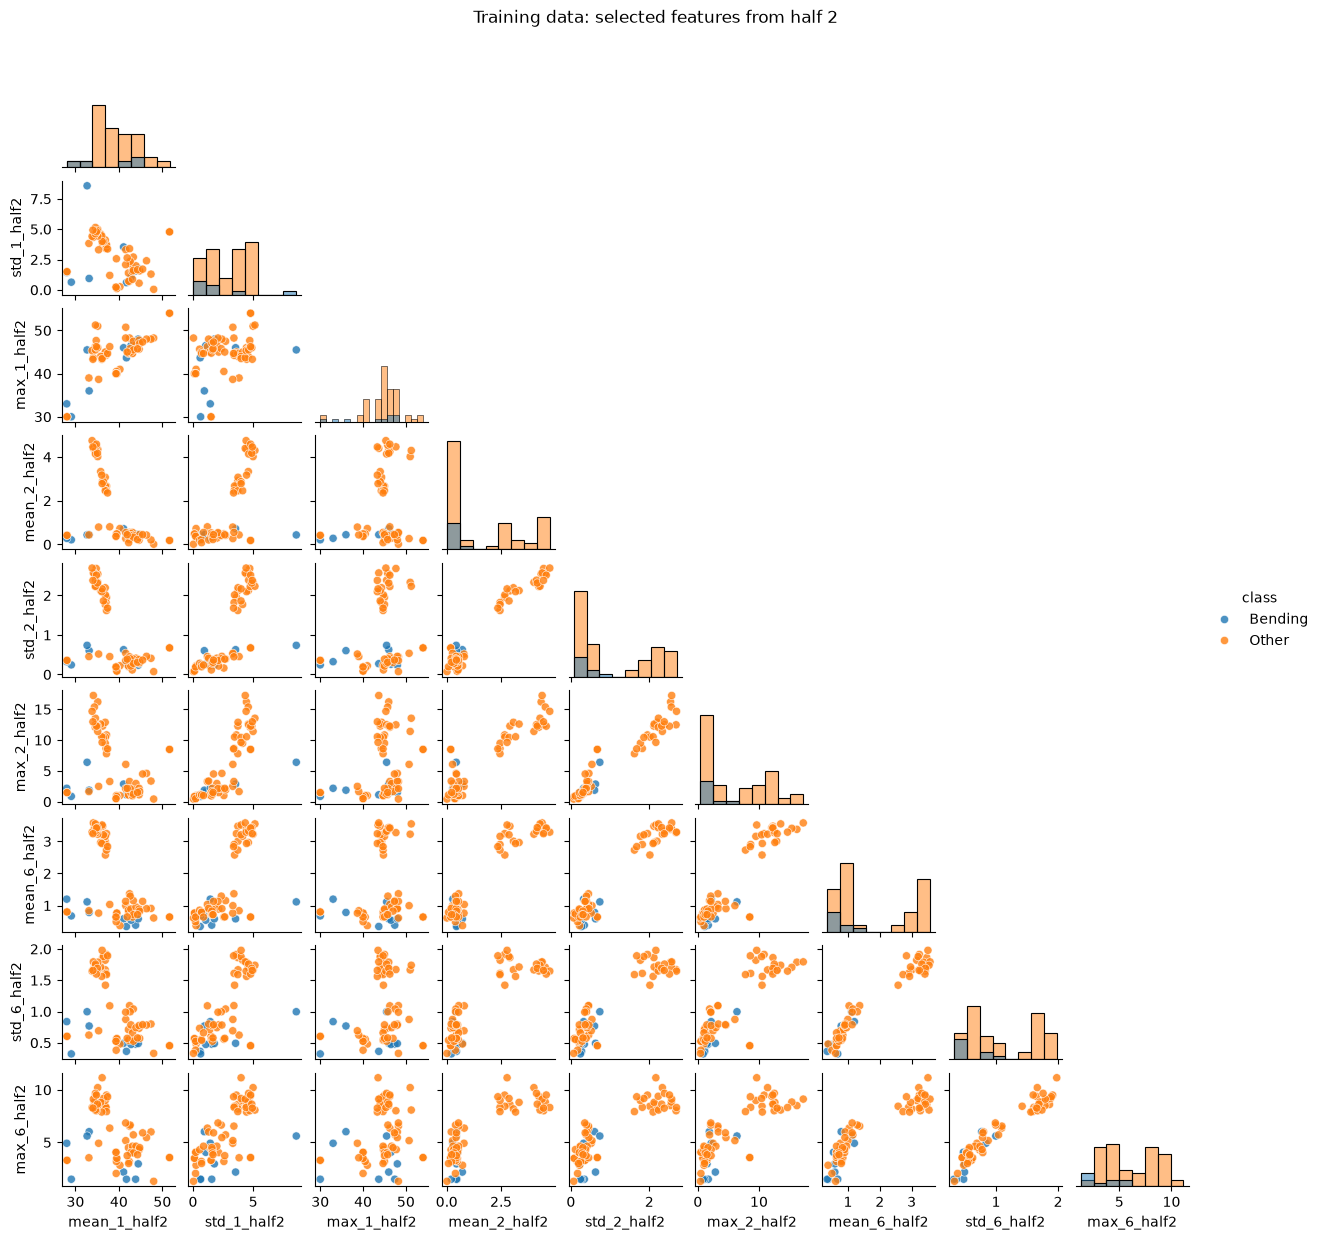

In [19]:
def extract_selected_halves(df):
    out = {}
    for j, name in enumerate(SERIES, start=1):
        if j not in [1, 2, 6]:
            continue
        halves = np.array_split(df[name].to_numpy(), 2)
        for h, vals in enumerate(halves, start=1):
            for stat, value in [("mean", vals.mean()), ("std", vals.std(ddof=1)), ("max", vals.max())]:
                out[f"{stat}_{j}_half{h}"] = value
    return out

half_X = pd.DataFrame([extract_selected_halves(x["data"]) for x in instances])
half_cols = list(half_X.columns)
half_df = half_X.loc[train_idx].copy()
half_df["class"] = labels_binary
for half in [1, 2]:
    cols = [col for col in half_cols if col.endswith(f"half{half}")]
    sns.pairplot(half_df, vars=cols, hue="class", corner=True, diag_kind="hist", height=1.35,
                 plot_kws={"alpha": 0.8, "s": 35})
    plt.suptitle(f"Training data: selected features from half {half}", y=1.02)
    plt.show()


**Comparison:** The two halves show roughly the same pattern as the full-series plots. Series 2 still separates some groups, but there is overlap and I do not see a clear overall improvement from splitting the recordings.


### Helper: segment-level features
For each instance and each `l`, every sensor series is split into `l` consecutive, approximately equal-sized pieces. Seven time-domain statistics are computed in each piece. Feature extraction uses each recording independently, so it does not learn from the test labels.

In [20]:
SEGMENT_STATS = ["min", "max", "mean", "median", "std", "q1", "q3"]
def segment_features(df, l):
    out = {}
    for j, name in enumerate(SERIES, start=1):
        for seg, vals in enumerate(np.array_split(df[name].to_numpy(), l), start=1):
            vals = pd.Series(vals)
            stats = {"min": vals.min(), "max": vals.max(), "mean": vals.mean(),
                     "median": vals.median(), "std": vals.std(ddof=1),
                     "q1": vals.quantile(.25), "q3": vals.quantile(.75)}
            for stat in SEGMENT_STATS:
                out[f"{stat}_s{j}_p{seg}"] = stats[stat]
    return pd.Series(out, dtype=float)

# Precompute deterministic features for all 88 recordings at each l.
features_by_l = {l: pd.DataFrame([segment_features(x["data"], l) for x in instances])
                 for l in range(1, 21)}
print("Feature dimensions for l=1, 2, and 20:",
      {l: features_by_l[l].shape[1] for l in [1, 2, 20]})


Feature dimensions for l=1, 2, and 20: {1: 42, 2: 84, 20: 840}


### 2(a)(iii). Logistic regression with recursive feature elimination

I use 5-fold stratified cross-validation on the 69 training recordings to choose `l` and the number of RFE features `p`. Scaling and RFE are fitted inside each fold. I use balanced accuracy so the small bending class is counted in model selection.


In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
p_grid = [1, 2, 3, 5, 8, 12]
logit_grid = {"rfe__n_features_to_select": p_grid}
rfe_rows, rfe_searches = [], {}
for l, X_l in features_by_l.items():
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("rfe", RFE(LogisticRegression(C=100, solver="liblinear", max_iter=2000), step=0.5)),
        ("logit", LogisticRegression(C=100, solver="liblinear", max_iter=2000))
    ])
    search = GridSearchCV(pipe, logit_grid, cv=cv, scoring={"balanced_accuracy": "balanced_accuracy", "accuracy": "accuracy"},
                          n_jobs=-1, refit="balanced_accuracy", return_train_score=False)
    search.fit(X_l.loc[train_idx], y_train)
    rfe_searches[l] = search
    rfe_rows.append({"l": l, "p": search.best_params_["rfe__n_features_to_select"],
                     "cv_balanced_accuracy": search.best_score_, "cv_accuracy":
                     search.cv_results_["mean_test_accuracy"][search.best_index_]})
rfe_results = pd.DataFrame(rfe_rows).sort_values(["cv_balanced_accuracy", "l"], ascending=[False, True])
display(rfe_results.head(10).round(4))
best_rfe = rfe_results.iloc[0]
best_l_rfe, best_p = int(best_rfe.l), int(best_rfe.p)
rfe_model = rfe_searches[best_l_rfe].best_estimator_
print(f"Selected RFE model: l={best_l_rfe}, p={best_p}; CV balanced accuracy={best_rfe.cv_balanced_accuracy:.3f}")
rfe_results.to_csv(RESULTS_DIR / "binary_rfe_cv.csv", index=False)


,l,p,cv_balanced_accuracy,cv_accuracy
0,1,5,0.9833,0.9714
2,3,1,0.9500,0.9857
1,2,5,0.9000,0.9714
11,12,3,0.8833,0.9429
18,19,5,0.8833,0.9429
19,20,5,0.8833,0.9418
16,17,12,0.8750,0.9286
7,8,8,0.8500,0.9571
8,9,5,0.8500,0.9571
6,7,8,0.8417,0.9429


Selected RFE model: l=1, p=5; CV balanced accuracy=0.983


**Cross-validation:** The wrong way is to scale the full training set or select features before making the folds; information from a validation fold would leak into model fitting. Here, scaling and RFE are refitted within each fold, and the test set is left out of model selection. Stratification keeps bending represented in the folds. Since I choose the best settings from these CV scores, that best score can still be optimistic.


### 2(a)(iv–vi). Training results, coefficients, and separation


RFE logistic regression
Train confusion matrix [true rows 0/1, predicted columns 0/1]:
 [[60  0]
 [ 0  9]]
Train accuracy / balanced accuracy / ROC AUC: 1.0 1.0 1.0
Test confusion matrix:
 [[15  0]
 [ 0  4]]
Test accuracy / balanced accuracy / ROC AUC: 1.0 1.0 1.0


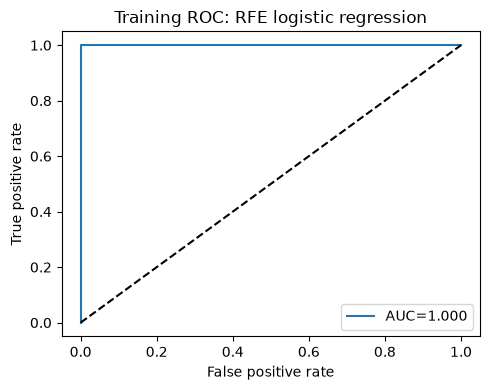

In [22]:
def eval_binary(model, Xtr, ytr, Xte, yte, title):
    model.fit(Xtr, ytr)
    prob_tr = model.predict_proba(Xtr)[:, 1]
    pred_tr = (prob_tr >= .5).astype(int)
    prob_te = model.predict_proba(Xte)[:, 1]
    pred_te = (prob_te >= .5).astype(int)
    print(title)
    print("Train confusion matrix [true rows 0/1, predicted columns 0/1]:\n", confusion_matrix(ytr, pred_tr))
    print("Train accuracy / balanced accuracy / ROC AUC:", accuracy_score(ytr, pred_tr),
          balanced_accuracy_score(ytr, pred_tr), roc_auc_score(ytr, prob_tr))
    print("Test confusion matrix:\n", confusion_matrix(yte, pred_te))
    print("Test accuracy / balanced accuracy / ROC AUC:", accuracy_score(yte, pred_te),
          balanced_accuracy_score(yte, pred_te), roc_auc_score(yte, prob_te))
    fpr, tpr, _ = roc_curve(ytr, prob_tr)
    plt.figure(figsize=(5, 4)); plt.plot(fpr, tpr, label=f"AUC={roc_auc_score(ytr, prob_tr):.3f}")
    plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
    plt.title(f"Training ROC: {title}"); plt.legend(); plt.tight_layout(); plt.show()
    return prob_tr, prob_te, pred_tr, pred_te

X_rfe = features_by_l[best_l_rfe]
rfe_prob_tr, rfe_prob_te, rfe_pred_tr, rfe_pred_te = eval_binary(
    rfe_model, X_rfe.loc[train_idx], y_train, X_rfe.loc[test_idx], y_test, "RFE logistic regression")


The table gives approximate Wald p-values for the selected, unpenalized model. They are conditional on the selected features and do not account for the feature-selection step. The large standard errors make these p-values unreliable if the classes are nearly separated.


In [23]:
def wald_table(X, y, feature_names):
    scaler = StandardScaler().fit(X)
    Z = scaler.transform(X)
    A = np.column_stack([np.ones(len(Z)), Z])
    result = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=200, tol=1e-8).fit(Z, y)
    beta = np.r_[result.intercept_[0], result.coef_[0]]
    p = expit(A @ beta)
    W = p * (1 - p)
    information = A.T @ (W[:, None] * A)
    cov = np.linalg.pinv(information)
    se = np.sqrt(np.maximum(np.diag(cov), 0))
    z = np.divide(beta, se, out=np.full_like(beta, np.nan), where=se > 0)
    pv = 2 * norm.sf(np.abs(z))
    names = ["intercept"] + list(feature_names)
    return result, pd.DataFrame({"feature": names, "coefficient_standardized": beta,
                                 "std_error_approx": se, "z_approx": z, "p_value_approx": pv})

selected_mask = rfe_model.named_steps["rfe"].support_
selected_names = X_rfe.columns[selected_mask]
# Fit the final unpenalized model on the selected original-scale features after standardization.
final_logit, coef_table = wald_table(X_rfe.loc[train_idx, selected_names], y_train, selected_names)
display(coef_table.round(5))
coef_table.to_csv(RESULTS_DIR / "binary_logit_coefficients_wald.csv", index=False)
print("Selected coefficients are standardized-unit log-odds effects. Wald p-values are approximate.")


,feature,coefficient_standardized,std_error_approx,z_approx,p_value_approx
0,intercept,-29.82529,2179.30513,-0.01369,0.98908
1,q3_s1_p1,-9.61981,1141.14220,-0.00843,0.99327
2,max_s4_p1,6.51091,1986.40186,0.00328,0.99738
3,min_s5_p1,16.67607,2403.10884,0.00694,0.99446
4,max_s5_p1,11.87027,2376.38439,0.00500,0.99601
5,q1_s6_p1,-17.31724,3781.70461,-0.00458,0.99635


Selected coefficients are standardized-unit log-odds effects. Wald p-values are approximate.


**Results and separation:** RFE gets 100% accuracy on both the training and test sets here. Its mean CV balanced accuracy is 0.983 (CV accuracy 0.971), compared with test accuracy 1.000. The selected model also has very large coefficient standard errors, which is consistent with near separation. These results are based on a small test set with only four bending recordings, so I would not treat the perfect test score as proof that the model will always work this well.


### 2(a)(vii). Case-control logistic regression

The training set has 60 other recordings and 9 bending recordings. I keep all bending cases and randomly sample 9 other cases, then adjust the intercept for the original training class proportion.


Training population prior: 0.1304 case-control prior: 0.5
Raw/adjusted intercept: 1.8379 -0.0592
Adjusted case-control test confusion matrix:
 [[14  1]
 [ 0  4]]
Test accuracy / balanced accuracy / ROC AUC: 0.9473684210526315 0.9666666666666667 1.0


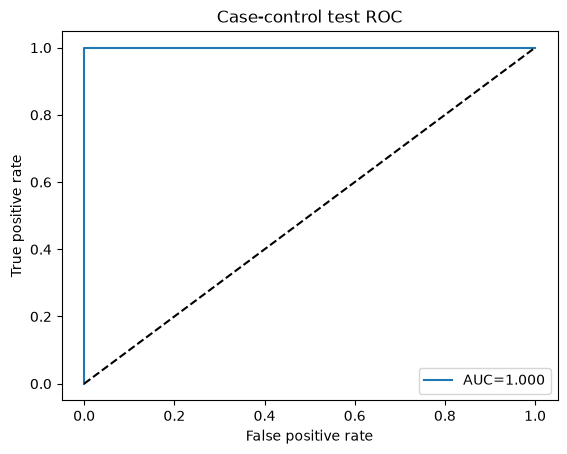

In [24]:
rng = np.random.default_rng(552)
pos = np.flatnonzero(y_train == 1); neg = np.flatnonzero(y_train == 0)
cc_idx = np.r_[pos, rng.choice(neg, size=len(pos), replace=False)]
X_cc = X_rfe.loc[train_idx].iloc[cc_idx][selected_names]
y_cc = y_train[cc_idx]
cc_scaler = StandardScaler().fit(X_cc)
cc_lr = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=1000).fit(cc_scaler.transform(X_cc), y_cc)
prior_pop = y_train.mean(); prior_cc = y_cc.mean()
intercept_adj = cc_lr.intercept_[0] + logit(prior_pop) - logit(prior_cc)
Xtest_cc = cc_scaler.transform(X_rfe.loc[test_idx, selected_names])
cc_prob_test = expit(intercept_adj + Xtest_cc @ cc_lr.coef_[0])
cc_pred_test = (cc_prob_test >= .5).astype(int)
print("Training population prior:", round(prior_pop, 4), "case-control prior:", round(prior_cc, 4))
print("Raw/adjusted intercept:", round(cc_lr.intercept_[0], 4), round(intercept_adj, 4))
print("Adjusted case-control test confusion matrix:\n", confusion_matrix(y_test, cc_pred_test))
print("Test accuracy / balanced accuracy / ROC AUC:", accuracy_score(y_test, cc_pred_test),
      balanced_accuracy_score(y_test, cc_pred_test), roc_auc_score(y_test, cc_prob_test))
fpr, tpr, _ = roc_curve(y_test, cc_prob_test)
plt.plot(fpr, tpr, label=f"AUC={roc_auc_score(y_test, cc_prob_test):.3f}"); plt.plot([0,1],[0,1],"k--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("Case-control test ROC"); plt.legend(); plt.show()


### 2(b). L1-penalized binary logistic regression

For each `l`, I tune `C` with 5-fold stratified CV. A smaller `C` gives stronger L1 regularization. Scaling is fitted inside each fold.


,l,C,cv_balanced_accuracy,cv_accuracy,nonzero_features
10,11,3.7276,0.9500,0.9857,11
11,12,0.7197,0.9500,0.9857,7
17,18,19.3070,0.9500,0.9857,21
0,1,0.7197,0.9417,0.9714,5
18,19,100.0000,0.9417,0.9714,41
19,20,19.3070,0.9417,0.9714,24
1,2,19.3070,0.9250,0.9429,12
12,13,0.7197,0.9000,0.9714,10
2,3,0.7197,0.8917,0.9571,8
3,4,100.0000,0.8917,0.9571,21


Selected L1 model: l=11, C=3.7276; CV balanced accuracy=0.950
L1 logistic regression
Train confusion matrix [true rows 0/1, predicted columns 0/1]:
 [[60  0]
 [ 0  9]]
Train accuracy / balanced accuracy / ROC AUC: 1.0 1.0 1.0
Test confusion matrix:
 [[15  0]
 [ 1  3]]
Test accuracy / balanced accuracy / ROC AUC: 0.9473684210526315 0.875 1.0


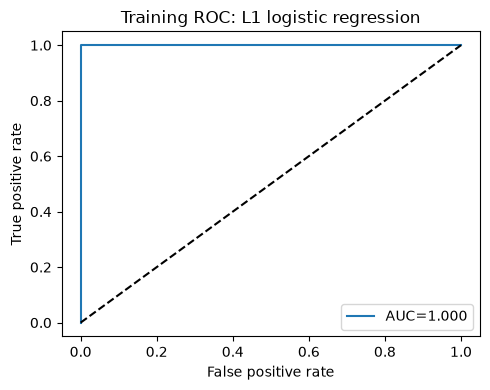

,method,CV balanced accuracy,CV accuracy,test accuracy,test balanced accuracy,test ROC AUC
0,RFE logistic,0.9833,0.9714,1.0000,1.000,1.0
1,L1 logistic,0.9500,0.9857,0.9474,0.875,1.0


In [25]:
C_grid = np.logspace(-3, 2, 8)
l1_rows, l1_searches = [], {}
for l, X_l in features_by_l.items():
    pipe = Pipeline([("scale", StandardScaler()),
                     ("logit", LogisticRegression(l1_ratio=1.0, solver="liblinear", max_iter=3000))])
    search = GridSearchCV(pipe, {"logit__C": C_grid}, cv=cv, scoring={"balanced_accuracy": "balanced_accuracy", "accuracy": "accuracy"},
                          n_jobs=-1, refit="balanced_accuracy")
    search.fit(X_l.loc[train_idx], y_train)
    l1_searches[l] = search
    l1_rows.append({"l": l, "C": search.best_params_["logit__C"],
                    "cv_balanced_accuracy": search.best_score_,
                    "cv_accuracy": search.cv_results_["mean_test_accuracy"][search.best_index_],
                    "nonzero_features": int(np.count_nonzero(search.best_estimator_.named_steps["logit"].coef_))})
l1_results = pd.DataFrame(l1_rows).sort_values(["cv_balanced_accuracy", "l"], ascending=[False, True])
display(l1_results.round(4))
best_l1 = int(l1_results.iloc[0].l)
l1_model = l1_searches[best_l1].best_estimator_
print(f"Selected L1 model: l={best_l1}, C={l1_results.iloc[0].C:.5g}; "
      f"CV balanced accuracy={l1_results.iloc[0].cv_balanced_accuracy:.3f}")
l1_results.to_csv(RESULTS_DIR / "binary_l1_cv.csv", index=False)
X_l1 = features_by_l[best_l1]
l1_prob_tr, l1_prob_te, l1_pred_tr, l1_pred_te = eval_binary(
    l1_model, X_l1.loc[train_idx], y_train, X_l1.loc[test_idx], y_test, "L1 logistic regression")

binary_comparison = pd.DataFrame([
    {"method": "RFE logistic", "CV balanced accuracy": float(best_rfe.cv_balanced_accuracy),
     "CV accuracy": float(best_rfe.cv_accuracy),
     "test accuracy": accuracy_score(y_test, rfe_pred_te),
     "test balanced accuracy": balanced_accuracy_score(y_test, rfe_pred_te),
     "test ROC AUC": roc_auc_score(y_test, rfe_prob_te)},
    {"method": "L1 logistic", "CV balanced accuracy": float(l1_results.iloc[0].cv_balanced_accuracy),
     "CV accuracy": float(l1_results.iloc[0].cv_accuracy),
     "test accuracy": accuracy_score(y_test, l1_pred_te),
     "test balanced accuracy": balanced_accuracy_score(y_test, l1_pred_te),
     "test ROC AUC": roc_auc_score(y_test, l1_prob_te)}])
display(binary_comparison.round(4))
binary_comparison.to_csv(RESULTS_DIR / "binary_model_comparison.csv", index=False)


**Comparison with RFE:** RFE has higher test accuracy (1.000 vs. 0.947) and balanced accuracy (1.000 vs. 0.875) on this split. Its CV balanced accuracy is also higher (0.983 vs. 0.950), though its CV accuracy is slightly lower (0.971 vs. 0.986). Both models have test AUC 1.000. With only four bending test cases, these differences are not conclusive. L1 is more direct to implement; RFE lets me set the number of retained features.


### 2(c). Multiclass classification

I use `l=11`, selected by the binary L1 analysis, and fit an L1 multinomial logistic model for the seven activities. I tune `C` by stratified cross-validation on the training set and show one-vs-rest ROC curves on the test set.


Selected l, C: 11 0.3981071705534973
CV accuracy: 0.7982
Test error: 0.0526
Test confusion matrix (rows=true, columns=predicted):
 [[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 0 0 3 0]
 [0 0 0 0 0 0 3]]
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.00      1.00      1.00         2
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       1.00      0.67      0.80         3
    standing       0.75      1.00      0.86         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.95        19
   macro avg       0.96      0.95      0.95        19
weighted avg       0.96      0.95      0.95        19



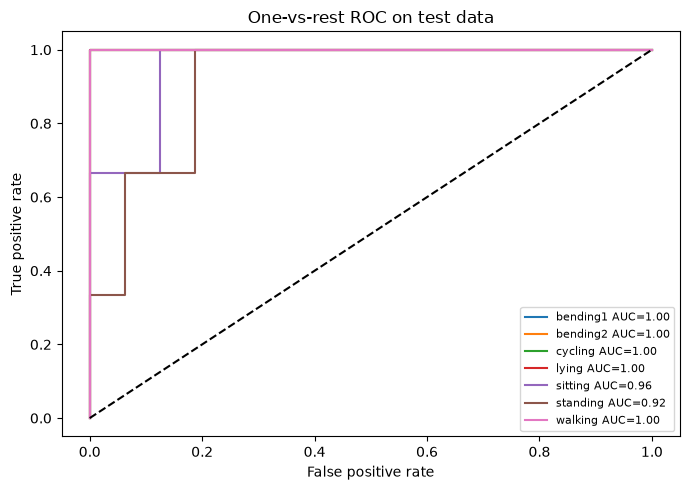

Macro one-vs-rest AUC over classes with both outcomes: 0.9821428571428571


In [26]:
y_multi = np.array([x["activity"] for x in instances])
y_multi_train, y_multi_test = y_multi[train_idx], y_multi[test_idx]
X_multi = features_by_l[best_l1]
Cs_multi = np.logspace(-2, 2, 6)
multi_pipe = Pipeline([("scale", StandardScaler()),
                      ("logit", LogisticRegression(l1_ratio=1.0, solver="saga",
                                                     max_iter=10000, tol=1e-3))])
# Bending2 has only four training recordings, so use 4 folds to keep it in every fold.
multi_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=552)
multi_search = GridSearchCV(multi_pipe, {"logit__C": Cs_multi}, cv=multi_cv,
                            scoring="accuracy", n_jobs=-1, refit=True)
multi_search.fit(X_multi.loc[train_idx], y_multi_train)
multi_model = multi_search.best_estimator_
multi_pred = multi_model.predict(X_multi.loc[test_idx])
multi_prob = multi_model.predict_proba(X_multi.loc[test_idx])
classes = multi_model.named_steps["logit"].classes_
print("Selected l, C:", best_l1, multi_search.best_params_["logit__C"])
print("CV accuracy:", round(multi_search.best_score_, 4))
print("Test error:", round(1-accuracy_score(y_multi_test, multi_pred), 4))
print("Test confusion matrix (rows=true, columns=predicted):\n", confusion_matrix(y_multi_test, multi_pred, labels=classes))
print(classification_report(y_multi_test, multi_pred, labels=classes, zero_division=0))
# One-vs-rest multiclass ROC/AUC.
y_bin = label_binarize(y_multi_test, classes=classes)
plt.figure(figsize=(7,5)); aucs=[]
for k, label in enumerate(classes):
    if len(np.unique(y_bin[:,k])) < 2: continue
    fpr, tpr, _ = roc_curve(y_bin[:,k], multi_prob[:,k])
    score = roc_auc_score(y_bin[:,k], multi_prob[:,k]); aucs.append(score)
    plt.plot(fpr, tpr, label=f"{label} AUC={score:.2f}")
plt.plot([0,1],[0,1],"k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("One-vs-rest ROC on test data"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()
print("Macro one-vs-rest AUC over classes with both outcomes:", np.mean(aucs))


### 2(c)(ii–iii). Gaussian and Multinomial Naive Bayes

I use the same `l=11` features for both Naive Bayes models. I standardize the inputs for GaussianNB. MultinomialNB needs nonnegative inputs, so I use the unscaled segment statistics.


In [27]:
# Gaussian Naive Bayes with fold-specific standardization.
gnb = Pipeline([("scale", StandardScaler()), ("nb", GaussianNB())])
gnb.fit(X_multi.loc[train_idx], y_multi_train)
gnb_pred = gnb.predict(X_multi.loc[test_idx])
gnb_prob = gnb.predict_proba(X_multi.loc[test_idx])

# MultinomialNB uses unscaled nonnegative statistics.
assert (X_multi.to_numpy() >= 0).all(), "MultinomialNB requires nonnegative predictors."
mnb = MultinomialNB().fit(X_multi.loc[train_idx], y_multi_train)
mnb_pred = mnb.predict(X_multi.loc[test_idx])
mnb_prob = mnb.predict_proba(X_multi.loc[test_idx])

nb_summary = pd.DataFrame([
    {"model":"L1 multinomial logistic", "test_error":1-accuracy_score(y_multi_test,multi_pred),
     "test_accuracy":accuracy_score(y_multi_test,multi_pred)},
    {"model":"Gaussian Naive Bayes", "test_error":1-accuracy_score(y_multi_test,gnb_pred),
     "test_accuracy":accuracy_score(y_multi_test,gnb_pred)},
    {"model":"Multinomial Naive Bayes", "test_error":1-accuracy_score(y_multi_test,mnb_pred),
     "test_accuracy":accuracy_score(y_multi_test,mnb_pred)}])
display(nb_summary.round(4))
for name, pred in [("GaussianNB", gnb_pred), ("MultinomialNB", mnb_pred)]:
    print(name, "confusion matrix:\n", confusion_matrix(y_multi_test, pred, labels=classes))
nb_summary.to_csv(RESULTS_DIR / "multiclass_model_comparison.csv", index=False)


,model,test_error,test_accuracy
0,L1 multinomial logistic,0.0526,0.9474
1,Gaussian Naive Bayes,0.4211,0.5789
2,Multinomial Naive Bayes,0.1579,0.8421


GaussianNB confusion matrix:
 [[0 0 0 1 1 0 0]
 [0 0 0 0 2 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 2 1 0 0]
 [0 0 0 0 2 1 0]
 [0 0 1 0 1 1 0]
 [0 0 0 0 0 0 3]]
MultinomialNB confusion matrix:
 [[2 0 0 0 0 0 0]
 [2 0 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 0 0 3 0]
 [0 0 0 0 0 0 3]]


**Which method did better?** On this test split, multinomial logistic regression has the lowest error (0.053), followed by MultinomialNB (0.158) and GaussianNB (0.421). The logistic model has the strongest result here, but the test set has only 19 recordings, so this is a comparison on this split rather than a precise estimate of future performance.


## 3. ISLR Chapter 4, Exercise 3
A logistic regression model uses $\hat\beta_0=-6$, $\hat\beta_1=0.05$, and $\hat\beta_2=1$, where $X_1$ is hours studied and $X_2$ is undergraduate GPA.

(a) For 40 hours and GPA 3.5, $\hat\eta=-6+0.05(40)+3.5= -0.5$. Thus $\hat p=1/(1+e^{0.5})\approx0.378$.

(b) For a 50% chance, the logit must be 0. Holding GPA at 3.5, solve $-6+0.05X_1+3.5=0$, giving $X_1=50$ study hours.

## 4. ISLR Chapter 4, Exercise 7
Let $Y=1$ denote issuing a dividend. The class priors are $P(Y=1)=0.8$ and $P(Y=0)=0.2$. Both classes have variance 36, with means 10 and 0. By Bayes’ theorem,

$$P(Y=1\mid X=4)=\frac{0.8\exp[-(4-10)^2/(2\cdot36)]}{0.8\exp[-(4-10)^2/(2\cdot36)]+0.2\exp[-(4-0)^2/(2\cdot36)]}\approx 0.752.$$

Thus, the estimated probability that the company issues a dividend is about **75.2%**.


## Reproducibility and AI use

Run the notebook from top to bottom with the data folders in `AReM/`. Tables are saved in `results/`.

**AI use:** AI helped generate and debug some code and draft explanations. I also used AI to check the notebook against the assignment; I will verify the results and be ready to explain the work I submit.
